# 03 — Profiling and validation

**Class 6 deliverable.** Profile the data, identify meaningful quality issues,
define business-oriented validation rules, and record assumptions rather than
silently fixing them.

**Governing principle: flag, never silently drop.** Every rule writes a boolean
column; no rule deletes a row. This is what keeps the KPI's denominator auditable.

In [1]:
import sys, json, duckdb, pandas as pd
sys.path.insert(0, '../src')
from pipeline.config import load_config
cfg = load_config('../config/pipeline.yaml')
con = duckdb.connect()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
RAW, MARTS, STG = '../data/raw', '../data/marts', '../data/staging'

## 1. Profile: what is actually in the data?

In [2]:
prof = con.sql(f'''
    SELECT count(*) AS rows,
           round(100.0*count(*) FILTER (WHERE passenger_count IS NULL)/count(*), 2) AS pax_null_pct,
           round(min(trip_distance), 2) AS dist_min, round(max(trip_distance), 1) AS dist_max,
           round(min(total_amount), 2) AS amt_min,  round(max(total_amount), 1) AS amt_max,
           min(tpep_pickup_datetime) AS first_pickup, max(tpep_pickup_datetime) AS last_pickup
    FROM read_parquet('{RAW}/trips/yellow/2024-01.parquet')
''').df()
display(prof.T.rename(columns={0: 'yellow 2024-01'}))

,yellow 2024-01
rows,2964624
pax_null_pct,4.73
dist_min,0.0
dist_max,312722.3
amt_min,-900.0
amt_max,5000.0
first_pickup,2002-12-31 22:59:39
last_pickup,2024-02-01 00:01:15


Three problems are already visible in that one table:

- `trip_distance` reaches into the hundreds of thousands of miles — impossible.
- `total_amount` goes **negative** — refunds booked against the original trip.
- pickup timestamps fall outside January — stray rows from adjacent months.

Each becomes a rule, and each rule needs a *business* decision, not just a filter.

## 2. The speed distribution — and where to put the KPI threshold

In [3]:
speed = con.sql(f'''
    WITH t AS (SELECT trip_distance d,
                      date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime)/3600.0 h
               FROM read_parquet('{RAW}/trips/yellow/2024-01.parquet'))
    SELECT round(quantile_cont(d/h, 0.10), 1) p10, round(quantile_cont(d/h, 0.25), 1) p25,
           round(median(d/h), 1) p50, round(quantile_cont(d/h, 0.75), 1) p75,
           round(quantile_cont(d/h, 0.90), 1) p90
    FROM t WHERE h > 0 AND d > 0 AND d < 100 AND h*60 BETWEEN 1 AND 180
''').df()
display(speed)
print("Median trip speed is ~9.7 mph. The 8 mph threshold sits just below it -")
print("calibrated to the data, not chosen for roundness.")

,p10,p25,p50,p75,p90
0,5.7,7.4,9.7,13.1,20.2


Median trip speed is ~9.7 mph. The 8 mph threshold sits just below it -
calibrated to the data, not chosen for roundness.


## 3. Rule hit rates, measured before the limits were set

In [4]:
q = con.sql(f'''
    WITH t AS (SELECT *, date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime)/60.0 dur
               FROM read_parquet('{RAW}/trips/yellow/2024-01.parquet'))
    SELECT round(100.0*count(*) FILTER (WHERE tpep_dropoff_datetime <= tpep_pickup_datetime)/count(*), 3) V01,
           round(100.0*count(*) FILTER (WHERE dur > 180 OR dur < 1)/count(*), 3) V02,
           round(100.0*count(*) FILTER (WHERE trip_distance <= 0 OR trip_distance > 100)/count(*), 3) V03,
           round(100.0*count(*) FILTER (WHERE dur > 0 AND trip_distance/(dur/60.0) > 80)/count(*), 3) V04,
           round(100.0*count(*) FILTER (WHERE tpep_pickup_datetime < '2024-01-01'
                                          OR tpep_pickup_datetime >= '2024-02-01')/count(*), 3) V05,
           round(100.0*count(*) FILTER (WHERE PULocationID IN (264,265) OR DOLocationID IN (264,265))/count(*), 3) V06,
           round(100.0*count(*) FILTER (WHERE total_amount < 0)/count(*), 3) V07,
           round(100.0*count(*) FILTER (WHERE passenger_count IS NULL OR passenger_count = 0)/count(*), 3) V08
    FROM t
''').df()
display(q.T.rename(columns={0: 'hit rate %'}))

,hit rate %
V01,0.029
V02,1.252
V03,2.038
V04,0.037
V05,0.001
V06,1.063
V07,1.198
V08,5.789


Abort limits in `config/pipeline.yaml` were set **after** measuring these, with
deliberate headroom. They exist to catch a *structural break* — a corrupt extract,
a vendor change — not ordinary month-to-month noise. A limit set below the normal
rate would make the pipeline cry wolf until someone disabled the check.

## 4. The two rules that are *not* simple exclusions

In [5]:
dq = con.sql(f"SELECT * FROM read_parquet('{MARTS}/m_data_quality/**/*.parquet')").df()
summary = (dq.groupby(['rule_id', 'action'])
             .apply(lambda g: 100*g.hits.sum()/g.total_trips.sum(), include_groups=False)
             .round(3).rename('pct_of_all_trips').reset_index()
             .sort_values('pct_of_all_trips', ascending=False))
display(summary)

,rule_id,action,pct_of_all_trips
7,V08_missing_passenger_count,flag_only,10.712
2,V03_distance_out_of_range,exclude_core,1.853
1,V02_duration_out_of_range,exclude_core,1.258
6,V07_negative_total,exclude_fare,1.251
5,V06_unknown_zone,exclude_zone,1.030
3,V04_implausible_speed,exclude_core,0.038
0,V01_dropoff_before_pickup,exclude_core,0.032
4,V05_pickup_outside_month,exclude_core,0.001


**V06 (unknown zone) → `exclude_zone`.** The trip is real and its speed is valid,
so it stays in citywide metrics — but it cannot be attributed to a borough.
Dropping it entirely would understate citywide volume; keeping it as a "zone"
would invent a phantom borough.

**V07 (negative total) → `exclude_fare`.** A refund is a real journey that really
happened at a real speed. It is removed from *fare* averages only.

This is why three population flags exist rather than one `is_valid`. Different
metrics legitimately have different denominators — and each published metric
carries its own `trips` count so the denominator is never ambiguous.

## 5. The finding that justified the whole approach

In [6]:
v08 = (dq[dq.rule_id == 'V08_missing_passenger_count']
       .groupby('month').apply(lambda g: 100*g.hits.sum()/g.total_trips.sum(), include_groups=False)
       .round(2).rename('V08_pct').reset_index())
display(v08)

,month,V08_pct
0,2024-01,5.81
1,2024-02,7.29
2,2024-03,12.89
3,2024-04,12.62
4,2024-05,11.81
5,2024-06,12.49


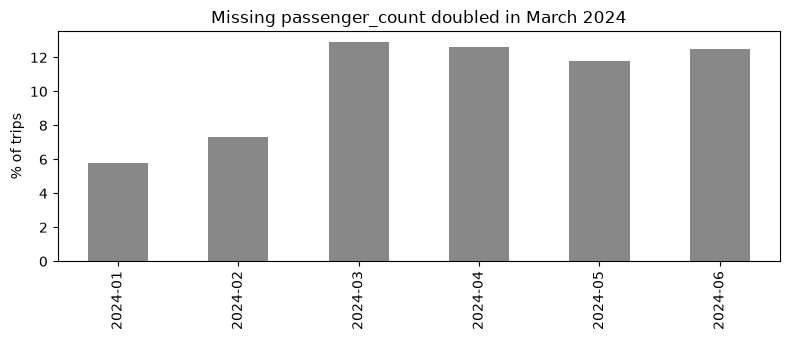

In [7]:
ax = v08.set_index('month').plot(kind='bar', figsize=(8, 3.5), legend=False,
                                 color=['#888']*2 + ['#c0392b']*4)
ax.set_title('Missing passenger_count doubled in March 2024')
ax.set_ylabel('% of trips'); ax.set_xlabel('')
import matplotlib.pyplot as plt; plt.tight_layout(); plt.show()

**Missing `passenger_count` doubled — 5.8% in January to ~12.5% from March on.**
This is a change in the upstream vendor feed, not in traffic.

Had V08 been an exclusion rule, the pipeline would have started discarding ~12% of
trips from March onward, and **the KPI would have shifted mid-series for reasons
having nothing to do with congestion.** The break would have been invisible in the
headline number and very hard to diagnose later.

Because the rule only *flags*, the break surfaces in `m_data_quality` where it
belongs, and the KPI is untouched. This is the concrete payoff of "flag, never
silently drop".

## 6. What the rules deliberately do *not* do

In [8]:
for rule in __import__('pipeline.validate', fromlist=['build_rules']).build_rules(cfg):
    print(f"{rule.id:<32} {rule.action:<14} {rule.rationale[:70]}...")

V01_dropoff_before_pickup        exclude_core   A trip cannot end before it starts; duration would be negative and wou...
V02_duration_out_of_range        exclude_core   Sub-minute trips are usually meter errors or immediate cancellations; ...
V03_distance_out_of_range        exclude_core   Zero distance means no journey took place; over 100 miles leaves the N...
V04_implausible_speed            exclude_core   Above 80 mph is not achievable on NYC streets; the distance or the tim...
V05_pickup_outside_month         exclude_core   The monthly extract is the unit of reprocessing; a trip from another m...
V06_unknown_zone                 exclude_zone   Zones 264/265 mean 'unknown' or 'outside NYC'. The trip is real and st...
V07_negative_total               exclude_fare   Negative totals are refunds and chargebacks booked against the origina...
V08_missing_passenger_count      flag_only      Passenger count is frequently unreported by the vendor system. It is n...


- **No imputation.** Imputing speed would manufacture the very quantity the KPI
  measures.
- **No outlier trimming on the KPI variable.** Slow trips are not outliers to be
  removed — they *are* the phenomenon. Only physically impossible speeds (V04) go,
  and the threshold is what a car can do, not a percentile of the data.
- **No deduplication.** Measured at zero; a dedup step would add risk with no
  benefit. Recorded as monitored assumption **A7**.